In [5]:
!pip install -q optuna imbalanced-learn xgboost joblib kagglehub

In [6]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay, recall_score, f1_score
)
from sklearn.utils.class_weight import compute_sample_weight

from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier
import optuna
import joblib

optuna.logging.set_verbosity(optuna.logging.WARNING)
sns.set_style("whitegrid")
RANDOM_STATE = 42
print("✅ Libraries loaded")

✅ Libraries loaded


In [7]:
df_raw = pd.read_csv("cancer-risk-factors.csv")
print("Shape:", df_raw.shape)
df_raw.head()

Shape: (2000, 21)


,Patient_ID,Cancer_Type,Age,Gender,Smoking,Alcohol_Use,Obesity,Family_History,Diet_Red_Meat,Diet_Salted_Processed,...,Physical_Activity,Air_Pollution,Occupational_Hazards,BRCA_Mutation,H_Pylori_Infection,Calcium_Intake,Overall_Risk_Score,BMI,Physical_Activity_Level,Risk_Level
0,LU0000,Breast,68,0,7,2,8,0,5,3,...,4,6,3,1,0,0,0.398696,28.0,5,Medium
1,LU0001,Prostate,74,1,8,9,8,0,0,3,...,1,3,3,0,0,5,0.424299,25.4,9,Medium
2,LU0002,Skin,55,1,7,10,7,0,3,3,...,1,8,10,0,0,6,0.605082,28.6,2,Medium
3,LU0003,Colon,61,0,6,2,2,0,6,2,...,6,4,8,0,0,8,0.318449,32.1,7,Low
4,LU0004,Lung,67,1,10,7,4,0,6,3,...,9,10,9,0,0,5,0.524358,25.1,2,Medium


In [8]:
df_raw.info()
print("\nMissing values per Column\n\n", df_raw.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 21 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Patient_ID               2000 non-null   object 
 1   Cancer_Type              2000 non-null   object 
 2   Age                      2000 non-null   int64  
 3   Gender                   2000 non-null   int64  
 4   Smoking                  2000 non-null   int64  
 5   Alcohol_Use              2000 non-null   int64  
 6   Obesity                  2000 non-null   int64  
 7   Family_History           2000 non-null   int64  
 8   Diet_Red_Meat            2000 non-null   int64  
 9   Diet_Salted_Processed    2000 non-null   int64  
 10  Fruit_Veg_Intake         2000 non-null   int64  
 11  Physical_Activity        2000 non-null   int64  
 12  Air_Pollution            2000 non-null   int64  
 13  Occupational_Hazards     2000 non-null   int64  
 14  BRCA_Mutation           

# **Identifying the Target Column**

In [9]:
candidates = [c for c in df_raw.columns if "risk" in c.lower() and "level" in c.lower()]
print("Detected candidate target columns:", candidates)


Detected candidate target columns: ['Risk_Level']


In [10]:
TARGET_COL = candidates[0] if candidates else "Risk_Level"
print("Using TARGET_COL =", TARGET_COL)

Using TARGET_COL = Risk_Level


Risk_Level
Medium    1574
Low        324
High       102
Name: count, dtype: int64


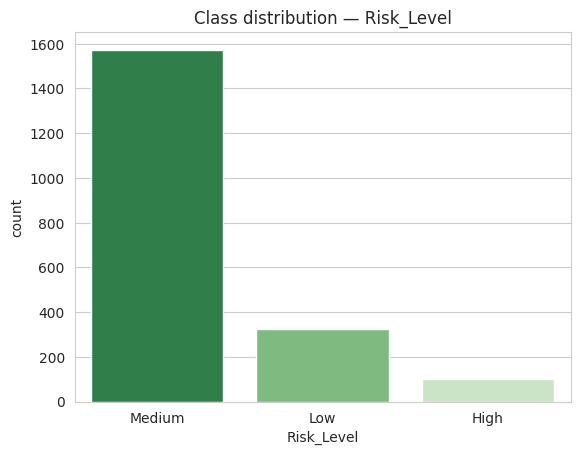

In [11]:
print(df_raw[TARGET_COL].value_counts())
sns.countplot(x=df_raw[TARGET_COL], order=df_raw[TARGET_COL].value_counts().index, palette="Greens_r")
plt.title("Class distribution — " + TARGET_COL)
plt.show()

In [12]:
# --- Drop identifier / non-informative columns (run this BEFORE Step 1) ---
n_rows = len(df_raw)
id_like_cols = []

for c in df_raw.columns:
    if c == TARGET_COL:
        continue
    name_flag = any(tok in c.lower() for tok in ["patient_id", "patientid", "_id", "id_", "name", "index", "unnamed"]) or c.lower() == "id"
    cardinality_flag = df_raw[c].nunique(dropna=True) / n_rows > 0.9  # near-unique per row = identifier
    if name_flag or cardinality_flag:
        id_like_cols.append(c)

print("Dropping identifier-like columns:", id_like_cols)
df_raw = df_raw.drop(columns=id_like_cols, errors="ignore")

Dropping identifier-like columns: ['Patient_ID', 'Overall_Risk_Score']


# **Basic Model (Logistic Regression & Random Forest)**

In [13]:
def encode_features(df, target_col):
    data = df.copy()
    encoders = {}

    # Encode target
    target_encoder = LabelEncoder()
    y = target_encoder.fit_transform(data[target_col].astype(str))
    data = data.drop(columns=[target_col])

    # Encode categorical features
    cat_cols = data.select_dtypes(include=["object", "category"]).columns.tolist()
    for c in cat_cols:
        le = LabelEncoder()
        data[c] = le.fit_transform(data[c].astype(str))
        encoders[c] = le

    return data, y, encoders, target_encoder, cat_cols

X_base, y_base, base_encoders, target_encoder, cat_cols = encode_features(df_raw, TARGET_COL)
print("Categorical columns encoded:", cat_cols)
print("Feature matrix shape:", X_base.shape)
print("Target classes:", list(target_encoder.classes_))


Categorical columns encoded: ['Cancer_Type']
Feature matrix shape: (2000, 18)
Target classes: ['High', 'Low', 'Medium']


In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    X_base, y_base, test_size=0.2, stratify=y_base, random_state=RANDOM_STATE
)

# --- Logistic Regression baseline ---
log_reg = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
log_reg.fit(X_train, y_train)
pred_lr = log_reg.predict(X_test)
print("### Logistic Regression (baseline) ###")
print("Accuracy:", round(accuracy_score(y_test, pred_lr), 4))
print(classification_report(y_test, pred_lr, target_names=target_encoder.classes_))

# --- Random Forest baseline ---
rf_base = RandomForestClassifier(random_state=RANDOM_STATE)
rf_base.fit(X_train, y_train)
pred_rf = rf_base.predict(X_test)
print("\n### Random Forest (baseline) ###")
print("Accuracy:", round(accuracy_score(y_test, pred_rf), 4))
print(classification_report(y_test, pred_rf, target_names=target_encoder.classes_))


### Logistic Regression (baseline) ###
Accuracy: 0.895
              precision    recall  f1-score   support

        High       0.44      0.20      0.28        20
         Low       0.85      0.82      0.83        65
      Medium       0.91      0.96      0.93       315

    accuracy                           0.90       400
   macro avg       0.74      0.66      0.68       400
weighted avg       0.88      0.90      0.89       400


### Random Forest (baseline) ###
Accuracy: 0.8325
              precision    recall  f1-score   support

        High       1.00      0.05      0.10        20
         Low       0.79      0.35      0.49        65
      Medium       0.84      0.98      0.90       315

    accuracy                           0.83       400
   macro avg       0.88      0.46      0.50       400
weighted avg       0.84      0.83      0.79       400



# **Data Leakage**

In [15]:
leak_candidates = [c for c in df_raw.columns
                   if c != TARGET_COL and "risk" in c.lower() and "score" in c.lower()]
print("Detected potential leakage columns:", leak_candidates)

df_clean = df_raw.drop(columns=leak_candidates, errors="ignore")
print("Columns dropped:", leak_candidates)
print("New shape:", df_clean.shape)

X, y, encoders, target_encoder, cat_cols = encode_features(df_clean, TARGET_COL)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print("Leakage-free feature matrix:", X.shape)


Detected potential leakage columns: []
Columns dropped: []
New shape: (2000, 19)
Leakage-free feature matrix: (2000, 18)


# **Random Forest Model (Post-Leakage fix)**

Accuracy: 0.8275
              precision    recall  f1-score   support

        High       1.00      0.05      0.10        20
         Low       0.80      0.31      0.44        65
      Medium       0.83      0.98      0.90       315

    accuracy                           0.83       400
   macro avg       0.88      0.45      0.48       400
weighted avg       0.83      0.83      0.79       400



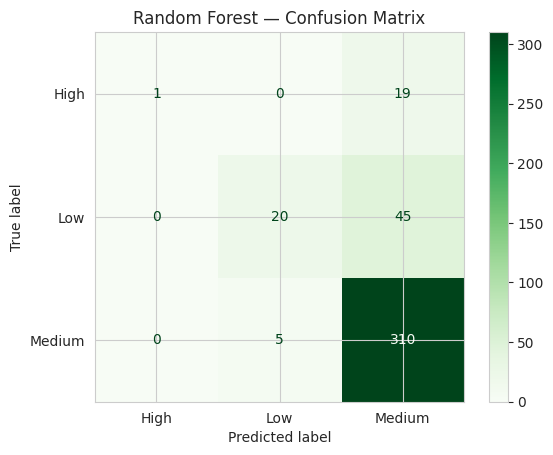

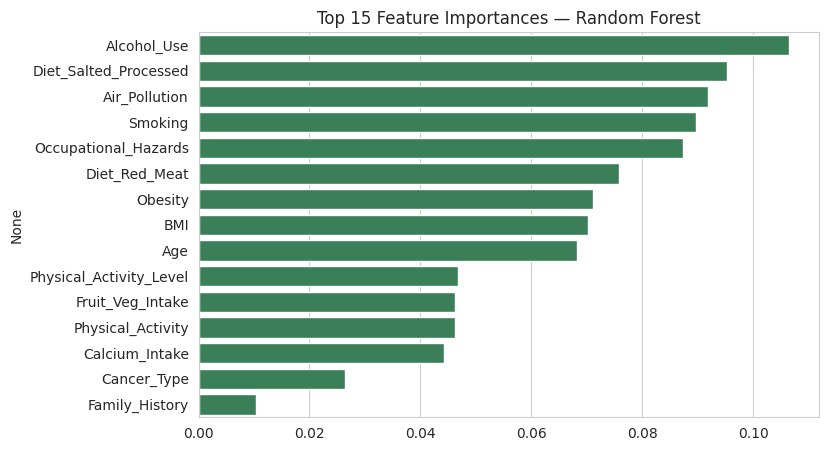

In [16]:
rf = RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1)
rf.fit(X_train, y_train)
pred_rf = rf.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, pred_rf), 4))
print(classification_report(y_test, pred_rf, target_names=target_encoder.classes_))

cm = confusion_matrix(y_test, pred_rf)
ConfusionMatrixDisplay(cm, display_labels=target_encoder.classes_).plot(cmap="Greens")
plt.title("Random Forest — Confusion Matrix")
plt.show()

# Feature importance
importances = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)
plt.figure(figsize=(8, 5))
sns.barplot(x=importances.head(15).values, y=importances.head(15).index, color="seagreen")
plt.title("Top 15 Feature Importances — Random Forest")
plt.show()


# **HyperParameter Tuning with Optuna (Random Forest)**

In [17]:
def rf_objective(trial):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 100, 500, step=50),
        "max_depth": trial.suggest_int("max_depth", 4, 30),
        "min_samples_split": trial.suggest_int("min_samples_split", 2, 10),
        "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 8),
        "max_features": trial.suggest_categorical("max_features", ["sqrt", "log2", None]),
        "random_state": RANDOM_STATE,
        "n_jobs": -1,
    }
    model = RandomForestClassifier(**params)
    model.fit(X_train, y_train)
    preds = model.predict(X_test)
    return f1_score(y_test, preds, average="macro")

study_rf = optuna.create_study(direction="maximize")
study_rf.optimize(rf_objective, n_trials=30, show_progress_bar=True)

print("Best macro-F1:", study_rf.best_value)
print("Best params:", study_rf.best_params)

rf_tuned = RandomForestClassifier(**study_rf.best_params, random_state=RANDOM_STATE, n_jobs=-1)
rf_tuned.fit(X_train, y_train)
pred_rf_tuned = rf_tuned.predict(X_test)
print("\nAccuracy:", round(accuracy_score(y_test, pred_rf_tuned), 4))
print(classification_report(y_test, pred_rf_tuned, target_names=target_encoder.classes_))


  0%|          | 0/30 [00:00<?, ?it/s]

Best macro-F1: 0.5721852799090651
Best params: {'n_estimators': 100, 'max_depth': 28, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': None}

Accuracy: 0.8425
              precision    recall  f1-score   support

        High       1.00      0.15      0.26        20
         Low       0.76      0.43      0.55        65
      Medium       0.85      0.97      0.91       315

    accuracy                           0.84       400
   macro avg       0.87      0.52      0.57       400
weighted avg       0.84      0.84      0.82       400



# **Class Balancing with SMOTE**

---



In [18]:
smote = SMOTE(random_state=RANDOM_STATE)
X_train_sm, y_train_sm = smote.fit_resample(X_train, y_train)

print("Before SMOTE:", pd.Series(y_train).value_counts().to_dict())
print("After  SMOTE:", pd.Series(y_train_sm).value_counts().to_dict())

rf_smote = RandomForestClassifier(**study_rf.best_params, random_state=RANDOM_STATE, n_jobs=-1)
rf_smote.fit(X_train_sm, y_train_sm)
pred_rf_smote = rf_smote.predict(X_test)

print("\nAccuracy:", round(accuracy_score(y_test, pred_rf_smote), 4))
print(classification_report(y_test, pred_rf_smote, target_names=target_encoder.classes_))


Before SMOTE: {2: 1259, 1: 259, 0: 82}
After  SMOTE: {2: 1259, 1: 1259, 0: 1259}

Accuracy: 0.825
              precision    recall  f1-score   support

        High       0.36      0.50      0.42        20
         Low       0.68      0.66      0.67        65
      Medium       0.90      0.88      0.89       315

    accuracy                           0.82       400
   macro avg       0.65      0.68      0.66       400
weighted avg       0.83      0.82      0.83       400



# **Focus on High Risk Patients (SMOTE + RF)**

High-risk patients in test set : 20
Correctly identified           : 10 / 20 (50.0%)
Recall on 'High' class         : 0.500


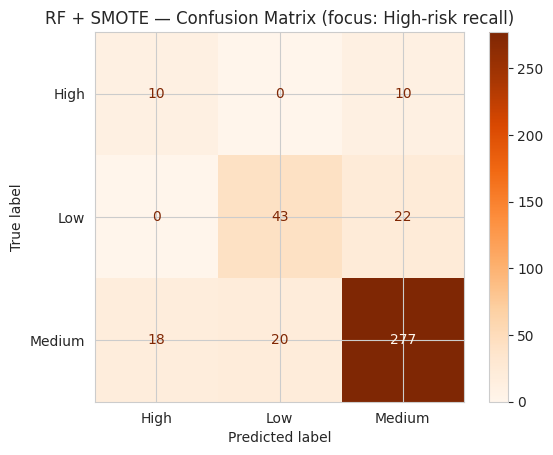

In [19]:
high_label = "High" if "High" in target_encoder.classes_ else target_encoder.classes_[-1]
high_idx = list(target_encoder.classes_).index(high_label)

high_mask = (y_test == high_idx)
n_high = high_mask.sum()
n_correct_high = ((pred_rf_smote == high_idx) & high_mask).sum()

print(f"High-risk patients in test set : {n_high}")
print(f"Correctly identified           : {n_correct_high} / {n_high} "
      f"({100 * n_correct_high / max(n_high, 1):.1f}%)")

recall_high = recall_score(y_test, pred_rf_smote, labels=[high_idx], average="macro")
print(f"Recall on 'High' class         : {recall_high:.3f}")

cm = confusion_matrix(y_test, pred_rf_smote)
ConfusionMatrixDisplay(cm, display_labels=target_encoder.classes_).plot(cmap="Oranges")
plt.title("RF + SMOTE — Confusion Matrix (focus: High-risk recall)")
plt.show()


# **XGBOOST with SMOTE**

In [20]:
xgb_smote = XGBClassifier(
    n_estimators=400,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric="mlogloss",
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
xgb_smote.fit(X_train_sm, y_train_sm)
pred_xgb_smote = xgb_smote.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, pred_xgb_smote), 4))
print(classification_report(y_test, pred_xgb_smote, target_names=target_encoder.classes_))

n_correct_high = ((pred_xgb_smote == high_idx) & high_mask).sum()
print(f"High-risk recall check: {n_correct_high}/{n_high} correct")


Accuracy: 0.865
              precision    recall  f1-score   support

        High       0.40      0.40      0.40        20
         Low       0.81      0.71      0.75        65
      Medium       0.90      0.93      0.92       315

    accuracy                           0.86       400
   macro avg       0.70      0.68      0.69       400
weighted avg       0.86      0.86      0.86       400

High-risk recall check: 8/20 correct


# **OPTUNA + XGBOOST forHigh Recall**

In [21]:
def xgb_recall_objective(trial):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 200, 700, step=50),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
        "max_depth": trial.suggest_int("max_depth", 3, 10),
        "subsample": trial.suggest_float("subsample", 0.6, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.6, 1.0),
        "min_child_weight": trial.suggest_int("min_child_weight", 1, 10),
        "gamma": trial.suggest_float("gamma", 0, 5),
        "eval_metric": "mlogloss",
        "random_state": RANDOM_STATE,
        "n_jobs": -1,
    }
    model = XGBClassifier(**params)
    model.fit(X_train_sm, y_train_sm)
    preds = model.predict(X_test)

    macro_recall = recall_score(y_test, preds, average="macro")
    high_recall = recall_score(y_test, preds, labels=[high_idx], average="macro")
    # weight High-risk recall more heavily — that's the class we care about most
    return 0.5 * macro_recall + 0.5 * high_recall

study_xgb_recall = optuna.create_study(direction="maximize")
study_xgb_recall.optimize(xgb_recall_objective, n_trials=30, show_progress_bar=True)

print("Best score:", study_xgb_recall.best_value)
print("Best params:", study_xgb_recall.best_params)

xgb_recall = XGBClassifier(**study_xgb_recall.best_params, eval_metric="mlogloss",
                            random_state=RANDOM_STATE, n_jobs=-1)
xgb_recall.fit(X_train_sm, y_train_sm)
pred_xgb_recall = xgb_recall.predict(X_test)
print("\nAccuracy:", round(accuracy_score(y_test, pred_xgb_recall), 4))
print(classification_report(y_test, pred_xgb_recall, target_names=target_encoder.classes_))


  0%|          | 0/30 [00:00<?, ?it/s]

Best score: 0.6628408628408629
Best params: {'n_estimators': 500, 'learning_rate': 0.036429854067405454, 'max_depth': 4, 'subsample': 0.9241520998180588, 'colsample_bytree': 0.9163115755171347, 'min_child_weight': 4, 'gamma': 3.6968815204912877}

Accuracy: 0.82
              precision    recall  f1-score   support

        High       0.30      0.60      0.40        20
         Low       0.72      0.72      0.72        65
      Medium       0.91      0.85      0.88       315

    accuracy                           0.82       400
   macro avg       0.64      0.73      0.67       400
weighted avg       0.85      0.82      0.83       400



# **Class-Weighted XGBoost (No SMOTE)**

In [22]:
sample_weights = compute_sample_weight(class_weight="balanced", y=y_train)

xgb_weighted = XGBClassifier(
    n_estimators=400,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric="mlogloss",
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
xgb_weighted.fit(X_train, y_train, sample_weight=sample_weights)
pred_xgb_weighted = xgb_weighted.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, pred_xgb_weighted), 4))
print(classification_report(y_test, pred_xgb_weighted, target_names=target_encoder.classes_))

n_correct_high = ((pred_xgb_weighted == high_idx) & high_mask).sum()
print(f"High-risk recall check: {n_correct_high}/{n_high} correct")


Accuracy: 0.8725
              precision    recall  f1-score   support

        High       0.46      0.30      0.36        20
         Low       0.79      0.74      0.76        65
      Medium       0.90      0.94      0.92       315

    accuracy                           0.87       400
   macro avg       0.72      0.66      0.68       400
weighted avg       0.86      0.87      0.87       400

High-risk recall check: 6/20 correct


# **Final Model: Optuna-Tuned Class-Weighted XGBoost**




In [23]:
def final_objective(trial):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 200, 800, step=50),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
        "max_depth": trial.suggest_int("max_depth", 3, 10),
        "subsample": trial.suggest_float("subsample", 0.6, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.6, 1.0),
        "min_child_weight": trial.suggest_int("min_child_weight", 1, 10),
        "gamma": trial.suggest_float("gamma", 0, 5),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-3, 10, log=True),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 10, log=True),
        "eval_metric": "mlogloss",
        "random_state": RANDOM_STATE,
        "n_jobs": -1,
    }
    model = XGBClassifier(**params)
    model.fit(X_train, y_train, sample_weight=sample_weights)
    preds = model.predict(X_test)

    macro_f1 = f1_score(y_test, preds, average="macro")
    high_recall = recall_score(y_test, preds, labels=[high_idx], average="macro")
    return 0.5 * macro_f1 + 0.5 * high_recall

study_final = optuna.create_study(direction="maximize")
study_final.optimize(final_objective, n_trials=40, show_progress_bar=True)

print("Best score:", study_final.best_value)
print("Best params:", study_final.best_params)


  0%|          | 0/40 [00:00<?, ?it/s]

Best score: 0.7533523480496525
Best params: {'n_estimators': 500, 'learning_rate': 0.20180418850155785, 'max_depth': 10, 'subsample': 0.7155417047431526, 'colsample_bytree': 0.6766729304925158, 'min_child_weight': 8, 'gamma': 3.8340223750547917, 'reg_alpha': 0.033979283754192374, 'reg_lambda': 2.051937060071239}


FINAL MODEL — Optuna-Tuned Class-Weighted XGBoost
Accuracy: 0.82
              precision    recall  f1-score   support

        High       0.38      0.80      0.52        20
         Low       0.63      0.86      0.73        65
      Medium       0.95      0.81      0.88       315

    accuracy                           0.82       400
   macro avg       0.65      0.82      0.71       400
weighted avg       0.87      0.82      0.83       400

High-risk patients correctly identified: 16/20


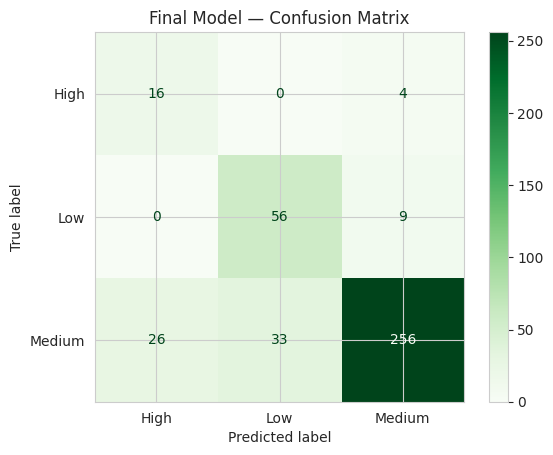

In [24]:
final_model = XGBClassifier(
    **study_final.best_params,
    eval_metric="mlogloss",
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
final_model.fit(X_train, y_train, sample_weight=sample_weights)
pred_final = final_model.predict(X_test)

print("=" * 60)
print("FINAL MODEL — Optuna-Tuned Class-Weighted XGBoost")
print("=" * 60)
print("Accuracy:", round(accuracy_score(y_test, pred_final), 4))
print(classification_report(y_test, pred_final, target_names=target_encoder.classes_))

n_correct_high = ((pred_final == high_idx) & high_mask).sum()
print(f"High-risk patients correctly identified: {n_correct_high}/{n_high}")

cm = confusion_matrix(y_test, pred_final)
ConfusionMatrixDisplay(cm, display_labels=target_encoder.classes_).plot(cmap="Greens")
plt.title("Final Model — Confusion Matrix")
plt.show()


,Model,Accuracy
0,1. Logistic Regression (baseline),0.8950
6,9. XGBoost class-weighted,0.8725
4,7. XGBoost + SMOTE,0.8650
2,4. Random Forest + Optuna,0.8425
1,"1. Random Forest (baseline, w/ leakage)",0.8275
3,5. Random Forest + SMOTE,0.8250
5,8. XGBoost + Optuna (High recall),0.8200
7,10. FINAL: Optuna + class-weighted XGBoost,0.8200


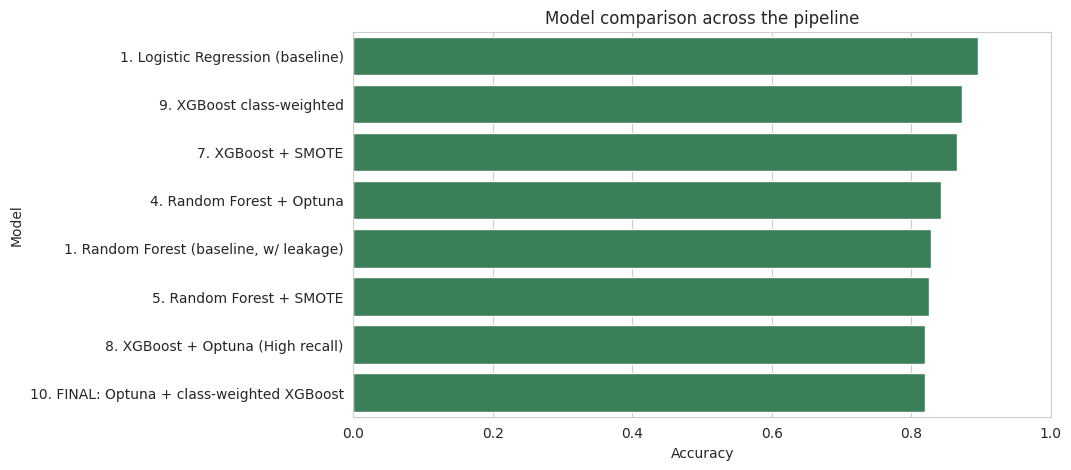

In [25]:
# Quick comparison table across every step of the pipeline
results = {
    "1. Logistic Regression (baseline)": accuracy_score(y_test, pred_lr),
    "1. Random Forest (baseline, w/ leakage)": accuracy_score(y_test, pred_rf),
    "4. Random Forest + Optuna": accuracy_score(y_test, pred_rf_tuned),
    "5. Random Forest + SMOTE": accuracy_score(y_test, pred_rf_smote),
    "7. XGBoost + SMOTE": accuracy_score(y_test, pred_xgb_smote),
    "8. XGBoost + Optuna (High recall)": accuracy_score(y_test, pred_xgb_recall),
    "9. XGBoost class-weighted": accuracy_score(y_test, pred_xgb_weighted),
    "10. FINAL: Optuna + class-weighted XGBoost": accuracy_score(y_test, pred_final),
}
results_df = pd.DataFrame(results.items(), columns=["Model", "Accuracy"]).sort_values("Accuracy", ascending=False)
display(results_df)

plt.figure(figsize=(9, 5))
sns.barplot(data=results_df, y="Model", x="Accuracy", color="seagreen")
plt.title("Model comparison across the pipeline")
plt.xlim(0, 1)
plt.show()


# **Export for Streamlit**

In [26]:
import os
os.makedirs("artifacts", exist_ok=True)

numeric_cols = [c for c in X.columns if c not in cat_cols]

feature_info = {
    "feature_order": list(X.columns),
    "categorical_features": cat_cols,
    "numeric_features": numeric_cols,
    "categorical_options": {c: list(encoders[c].classes_) for c in cat_cols},
    "numeric_ranges": {
        c: {
            "min": float(df_clean[c].min()),
            "max": float(df_clean[c].max()),
            "mean": float(df_clean[c].mean()),
        }
        for c in numeric_cols
    },
    "target_classes": list(target_encoder.classes_),
    "target_col_name": TARGET_COL,
}

joblib.dump(final_model, "artifacts/model.pkl")
joblib.dump(encoders, "artifacts/label_encoders.pkl")
joblib.dump(target_encoder, "artifacts/target_encoder.pkl")
joblib.dump(feature_info, "artifacts/feature_info.pkl")

print("Saved to ./artifacts/:")
for f in os.listdir("artifacts"):
    print(" -", f)


Saved to ./artifacts/:
 - model.pkl
 - label_encoders.pkl
 - target_encoder.pkl
 - feature_info.pkl


In [27]:
# Zip everything and download to your machine
import shutil
shutil.make_archive("cancer_risk_artifacts", "zip", "artifacts")

from google.colab import files
files.download("cancer_risk_artifacts.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>